# TDI filter sensitivity
In the new structure, PCI and TDI filters share a common infrastructure.  This notebook focuses on developing sensitivity curves calculations within the new structure.

Ultimately. The work here (minimally) shows that the sensitivity calculations provided by pcipy.sensitivity make sense and those should be used (see the end of this notebook), rather than taking this note as an example overall.

In [1]:
import jax
jax.config.update("jax_enable_x64", True)  #HACK: Some things are coming up zeros with jax, maybe this helps

import importlib
import os
from datetime import datetime

import json
import h5py
import numpy as np
import scipy
import matplotlib.pyplot as plt

from pytdi import Data

from pcipy.data import TimeData
from pcipy.tdi_filter import DeducedTDIFilter as TDIFilter
from pcipy.filter import PiecewiseFilter as PiecewiseFilter
from pcipy.local_pci_filter import LocalPCIFilter
import pcipy.sensitivity as sensitivity

import pyfftw
from pyfftw.interfaces.numpy_fft import rfft

## Read in data sets

In [2]:
#1. Read in data sets
SKIP = 1000

RANGE_IN_HOURS = 24*14

DATADIR = "/Users/jbaker/Projects/PCI/late-2025-work/pcipy/data/"
WORKDIR = DATADIR+"/simulations/"

MEASPATH = 'measurements_4Hz.h5'
TDIPATH = 'tdi2_4Hz.h5'
ORBPATH = 'keplerian'

substring = [ORBPATH + '_' +
             s for s in ['locking_N1-12_laser_tm_oms_', 'all_sky_gw_', 'gw_']]
# substring = ['locking_six_laser_tm_oms', 'all_sky_gw', '2_gw']
sims = ["noise", "all_sky", "point_source"]
datasets = dict(zip(sims, substring))

matchfile = {}
dtpath = {}

for n, d in zip(substring, datasets):
    timestamp = []
    matchfile[n] = [f for f in os.listdir(WORKDIR) if n in f]
    for m in matchfile[n]:
        # pick latest date
        timestamp.append(datetime.strptime(m[:11], "%Y-%m-%d_"))
        # print(n, timestamp[n])
        dtpath[d] = max(timestamp).strftime("%Y-%m-%d_")
print(dtpath)

orbits = WORKDIR + ORBPATH + "-orbits.h5"
noise_file_base = dtpath['noise'] + datasets['noise']
#gw_file_base = dtpath['all_sky'] + datasets['all_sky']
gw_file_base = dtpath['point_source'] + datasets['point_source']

{'noise': '2025-11-18_', 'all_sky': '2025-12-02_', 'point_source': '2025-12-02_'}


#### Basic single-link noise data

In [3]:
#2. Generate Basic single-link noise data

noise_sim_path = WORKDIR + noise_file_base + MEASPATH

# get the central frequency
with h5py.File(noise_sim_path, 'r') as sim:
    attributes = json.loads(sim.attrs['metadata_json'])
    central_freq = attributes['central_freq']
    fs = attributes['fs']

data_noise = Data.from_instrument(noise_sim_path)

in_chans = ["sci"]
in_chans = ["sci", "ref", "tmi"]
# in_chans=["isi","rfi","tmi","isi_sb","rfi_sb"]

in_chansGW = ["sci"]

def make_names(in_chans):
    """

    Parameters
    ----------
    in_chans : TYPE
        DESCRIPTION.

    Returns
    -------
    names : TYPE
        DESCRIPTION.

    """
    mosas_order = ['12', '23', '31', '13', '21', '32']
    names = []
    for chan in in_chans:
        for link in mosas_order:
            names.append(f'{chan}_{link}')
    return names

# setup instrumental channels
y_names = make_names(in_chans)
# divide by central_freq because simulation channels are in beat-rate units
y_list = [data_noise.measurements[name]/central_freq for name in y_names]
# create a TimeData object
y_n = TimeData(np.array(y_list, dtype=np.float64)[:, SKIP:],
               dt=1/fs,
               t0=SKIP/fs,
               names=y_names)

#### Matching GW simulations results for the empirical sensitivity calculation

In [4]:
# we need these only for the sensitivity calculation

gw_path = WORKDIR+gw_file_base+MEASPATH

data_gw = Data.from_gws(gw_path,orbits)

y_namesGW = make_names(in_chansGW)
# #note: the GW mesaurement data are already fractional frequency so we don't divide by central_freq
y_list = [data_gw.measurements[name] for name in y_namesGW]
print(y_namesGW, [np.shape(y) for y in y_list])

np.array(y_list, dtype=np.float64)
y_gw = TimeData(np.array(y_list, dtype=np.float64)[:,SKIP:],dt=1/fs,t0=SKIP/fs,names=y_namesGW)

You are using a GW file in a version that might not be fully supported
You are using an orbit file in a version that might not be fully supported


['sci_12', 'sci_23', 'sci_31', 'sci_13', 'sci_21', 'sci_32'] [(1036800,), (1036800,), (1036800,), (1036800,), (1036800,), (1036800,)]


#### For comparison, we also need the TDI data

In [5]:
#TDI noise from file
tdipath2 = WORKDIR +  noise_file_base + "noise_" + TDIPATH

tdi2 = h5py.File(tdipath2, 'r')
x2_noise = tdi2['x'][()] / central_freq
y2_noise = tdi2['y'][()] / central_freq
z2_noise = tdi2['z'][()] / central_freq
tdi2.close()

XYZ_file_noise = TimeData(np.array([x2_noise,y2_noise,z2_noise], dtype=np.float64)[:,SKIP:],dt=1/fs,t0=SKIP/fs,names='XYZ')

#GW
tdi2_gw_file = WORKDIR + gw_file_base + TDIPATH

hdf5 = h5py.File(tdi2_gw_file, 'r')
x2_gw = hdf5['x'][()] #/ central_freq  (gw simulation already in fractional freq)
y2_gw = hdf5['y'][()] #/ central_freq
z2_gw = hdf5['z'][()] #/ central_freq
hdf5.close()

XYZ_file_gw = TimeData(np.array([x2_gw,y2_gw,z2_gw], dtype=np.float64)[:,SKIP:],dt=1/fs,t0=SKIP/fs,names='XYZ')


#### Define data range for this study and set up fourier transforms

In [6]:
range_in_hours = 48
segment_hours = 4

nsegs = range_in_hours // segment_hours

ibuff=250   #edge buffer for kernels 

ns = int(range_in_hours * 3600 * fs) # less for dev

In [7]:

ytest_n = y_n.get_range(0,ns+2*ibuff)
ytest_gw = y_gw.get_range(0,ns+2*ibuff)

TDItest_n = XYZ_file_noise.get_range(0,ns+2*ibuff)
TDItest_gw = XYZ_file_gw.get_range(0,ns+2*ibuff)


In [8]:
#Fourier Transform
import pyfftw
from pyfftw.interfaces.numpy_fft import rfft, irfft, fft
pyfftw.interfaces.cache.enable()
# Transform PCI variables to Fourier domain

wd = np.blackman(ns)

## Transform simulated TDI variables to Fourier domain
k2 = np.sum(wd**2)

def do_ft(dataset, fs=fs):
    ns=dataset.n_samples()
    wd=np.blackman(ns)
    f = np.fft.rfftfreq(ns) * fs
    sel=f>0
    #print(sel)
    dataset_fft=[rfft(wd * dataset.data[i] ) * np.sqrt(2/(fs*k2)) for i in range(dataset.n_channels())]
    
    return f[sel], np.array(dataset_fft)[:,sel]

In [9]:
tbuff=0
tstart=ytest_n.t0 - tbuff
tend=ytest_n.t0+ytest_n.dt*ytest_n.n_samples()  + tbuff

pwTDIfilter=PiecewiseFilter(tstart,tend,nsegs,TDIFilter, measurements_data=data_noise,in_chans=in_chans,method='linear')

In [10]:
XYZpw=pwTDIfilter.apply_filter(ytest_n,check=True)

In [11]:
XYZparts = [filt.apply_filter(ytest_n) for filt in pwTDIfilter.subfilters]

For seg 6 of 12
min -6.369297363879759e-15
max 6.213628814048602e-15
mean 8.97101610416885e-22
std 8.270351493896606e-16
refshape: (68642,)
time offest check: 0.0
data shape: (68642,)
time offest check: 0.0
data shape: (68642,)
time offest check: 0.0
data shape: (68642,)
time offest check: 0.0
data shape: (68642,)
time offest check: 0.0
data shape: (68642,)
time offest check: 0.0
data shape: (68642,)
time offest check: 0.0
data shape: (68642,)
time offest check: 0.0
data shape: (68642,)
time offest check: 0.0
data shape: (68642,)
time offest check: 0.0
data shape: (68642,)
time offest check: 0.0
data shape: (68642,)
time offest check: 0.0
data shape: (68642,)
time offest check: 0.0
data shape: (68642,)
zsh:1: command not found: free


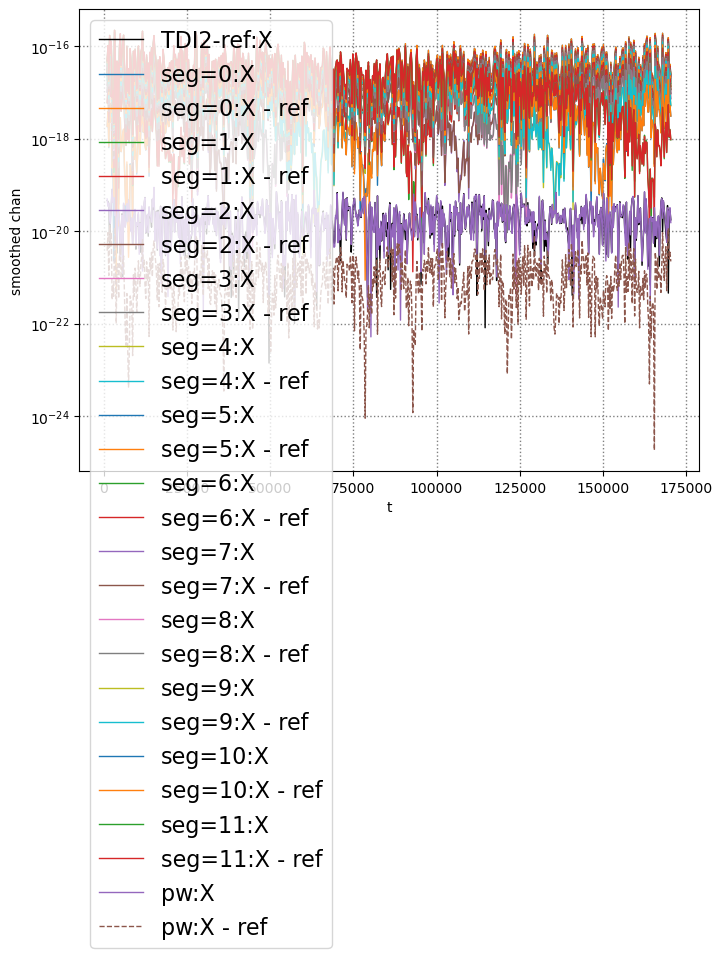

In [12]:
import scipy
# View data in decimated in the time domain

import matplotlib.pyplot as plt
# Comparison with TDI variables
_, axes = plt.subplots(1, 1, figsize=(8, 6))
colors = ['blue', 'skyblue', 'red', 'orange', 'purple', 'gray']
# TDI 2.0 

idec = 10
iev=100
ibegin=0
iend=1000000

ixyz=0
#iskip=249
iskip=282

ioff=len(TDItest_n.data[ixyz])

delta=XYZparts[nsegs//2].data[ixyz]-TDItest_n.data[ixyz][iskip:]
print('For seg',nsegs//2,'of',nsegs)
print('min',np.min(delta))
print('max',np.max(delta))
print('mean',np.mean(delta))
print('std',np.std(delta))

do_dec=lambda x:scipy.signal.decimate(x,q=idec)[ibuff:-ibuff]
#epsd=do_dec(eps[:])



data=do_dec(TDItest_n.data[ixyz][iskip:])
times=do_dec(TDItest_n.get_times()[iskip:])    
refdata=data
reftimes=times
print('refshape:',refdata.shape)

axes.semilogy(times[ibegin:iend:iev], np.abs(data[ibegin:iend:iev]), c='k', linewidth=1, label='TDI2-ref:'+'XYZ'[ixyz])

for iset in range(nsegs):
    data=do_dec(XYZparts[iset].data[ixyz])
    times=do_dec(XYZparts[iset].get_times())
    print('time offest check:', np.mean(times-reftimes))
    print('data shape:',data.shape)
    axes.semilogy(times[ibegin:iend:iev], np.abs(data[ibegin:iend:iev]), linewidth=1, label='seg='+str(iset)+':'+'XYZ'[ixyz])
    axes.semilogy(times[ibegin:iend:iev], 1e-25+np.abs((data-refdata)[ibegin:iend:iev]), linewidth=1, label='seg='+str(iset)+':'+'XYZ'[ixyz]+' - ref')
    #refdata=data

if 1:
    data=do_dec(XYZpw.data[ixyz])
    times=do_dec(XYZpw.get_times())
    print('time offest check:', np.mean(times-reftimes))
    print('data shape:',data.shape)
    axes.semilogy(times[ibegin:iend:iev], np.abs(data[ibegin:iend:iev]), linewidth=1, label='pw:'+'XYZ'[ixyz])
    axes.semilogy(times[ibegin:iend:iev], 1e-25+np.abs((data-refdata)[ibegin:iend:iev]), linewidth=1, ls='--', label='pw:'+'XYZ'[ixyz]+' - ref')
    
axes.set_xlabel(r"t")
axes.set_ylabel(r"smoothed chan")
plt.legend(loc='upper left', fontsize=16)
# axes.set_ylim([1e-24, 1e-17])
#axes.set_xlim([1e-4, 0.1])
#plt.title("PCI 2.0 (" + str(int(ns/fs/3600))+" hours, nh = "+str(nhalf)+")")
plt.grid(linewidth=1.0, 
         color='gray', 
         linestyle='dotted', 
         which='both', 
         axis='both')
#plt.show()
!free

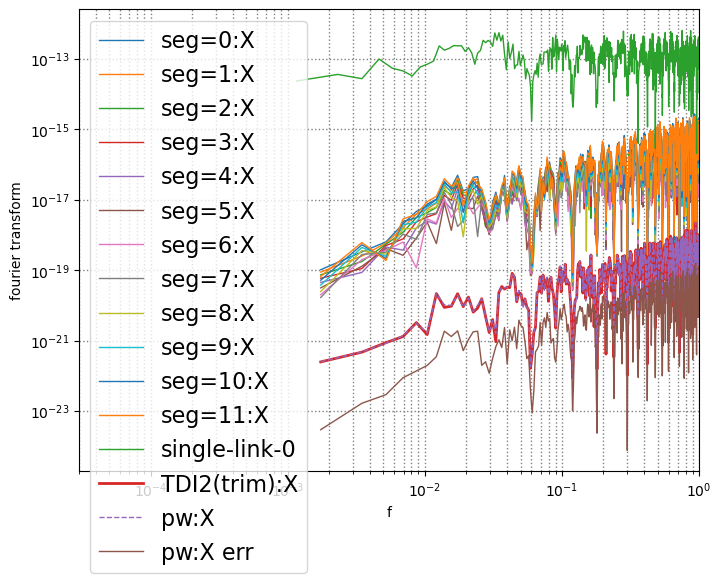

In [13]:
# View data in freq domain

import matplotlib.pyplot as plt
# Comparison with TDI variables
_, axes = plt.subplots(1, 1, figsize=(8, 6))
colors = ['blue', 'skyblue', 'red', 'orange', 'purple', 'gray']
# TDI 2.0 

iev = 300
i0=iev

ixyz=0

for iset in range(nsegs):
    f,data=do_ft(XYZparts[iset])
    axes.loglog(f[i0::iev], (1+iset*0)*np.abs(data[ixyz,i0::iev]), linewidth=1, label='seg='+str(iset)+':'+'XYZ'[ixyz])
               
for iy in range(1):
    f,data=do_ft(y_n)
    axes.loglog(f[i0::iev], (1+iset*0)*np.abs(data[iy,i0::iev]), linewidth=1, label="single-link-"+str(iy))


f,data=do_ft(TDItest_n.get_range(iskip,None))
dataref=data
axes.loglog(f[i0::iev], np.abs(dataref[ixyz,i0::iev]), linewidth=2, label='TDI2(trim):'+'XYZ'[ixyz])

f,data=do_ft(XYZpw)
axes.loglog(f[i0::iev], np.abs(data[ixyz,i0::iev]), linewidth=1, ls='--', label='pw:'+'XYZ'[ixyz])
data=data-dataref
axes.loglog(f[i0::iev], (1+iset*0)*np.abs(data[ixyz,i0::iev]), linewidth=1, label='pw:'+'XYZ'[ixyz]+' err')

if 0:
    for iset in range(nsegs):
        f,data=do_ft(XYZparts[iset])
        data=data-dataref
        axes.loglog(f[i0::iev], (1+iset*0)*np.abs(data[ixyz,i0::iev]), linewidth=1, label='seg='+str(iset)+':'+'XYZ'[ixyz]+' err')


axes.set_xlabel("f")
axes.set_ylabel(r"fourier transform")
plt.legend(loc='upper left', fontsize=16)
# axes.set_ylim([1e-24, 1e-17])
axes.set_xlim([.3e-4, 1])
#plt.title("PCI 2.0 (" + str(int(ns/fs/3600))+" hours, nh = "+str(nhalf)+")")
plt.grid(linewidth=1.0, 
         color='gray', 
         linestyle='dotted', 
         which='both', 
         axis='both')
#plt.show()

## Sensitivity estimates

In [14]:
from scipy import signal
from pcipy.filter import RestrictedFilter

# Some options and prep for the welch_matrix calc
nperseg = 200000
welch_kwargs = {"fs": fs,
          "window": 'blackman',
          "nperseg": nperseg,
          "detrend": 'constant',
          "return_onesided": True,
          "scaling": 'density'}
welch_kwargs['detrend']=None

def compute_welch_matrix(ydata, **kwargs):
    """
    Compute the welch estimated PSDs and CSDs of a multivariate time series.

    Parameters
    ----------
    ydata : ndarray
        array of time series, size n_samples x n_channels
    """

    fy, _ = signal.welch(ydata[:, 0], **kwargs)
    welch_mat = np.zeros((fy.shape[0], ydata.shape[1], ydata.shape[1]), dtype=np.complex128)

    for i in range(ydata.shape[1]):
        _, welch_mat[:, i, i] = signal.welch(ydata[:, i], **kwargs)

        for j in range(i+1, ydata.shape[1]):
            _, welch_mat[:, i, j] = signal.csd(ydata[:, i], ydata[:, j], **kwargs)
            welch_mat[:, j, i] = np.conjugate(welch_mat[:, i, j])

    return fy, welch_mat

def compute_welch_matrix_td(y_td, **kwargs):
    """
    Compute the welch estimated PSDs and CSDs of a multivariate time series.

    Parameters
    ----------
    ydata : ndarray
        array of time series, size n_samples x n_channels
    """

    args=kwargs.copy()
    args['fs']=1/y_td.dt
    
    ydata=y_td.data.T
    
    fy, _ = signal.welch(ydata[:, 0], **kwargs)
    welch_mat = np.zeros((fy.shape[0], ydata.shape[1], ydata.shape[1]), dtype=np.complex128)

    for i in range(ydata.shape[1]):
        _, welch_mat[:, i, i] = signal.welch(ydata[:, i], **kwargs)

        for j in range(i+1, ydata.shape[1]):
            _, welch_mat[:, i, j] = signal.csd(ydata[:, i], ydata[:, j], **kwargs)
            welch_mat[:, j, i] = np.conjugate(welch_mat[:, i, j])

    return fy, welch_mat

def multiple_dot(a_mat, b_mat):
    """
    Perform the matrix multiplication of two list of matrices.

    Parameters
    ----------
    a : ndarray
        series of m x n matrices (array of size p x m x n)
    b : ndarray
        series of n x k matrices (array of size p x n x k)

    Returns
    -------
    c : ndarray
        array of size p x m x k containg the dot products of all matrices
        contained in a and b.


    """

    return np.einsum("ijk, ikl -> ijl", a_mat, b_mat)

def estimate_sensitivity(filt, data_n, data_gw, joint=True, welch_kwargs=welch_kwargs, strainPSD=2):
    #Sensitivity is estimated by explicit computation of the ratio of the channel noise and channel simulated GW signal
    #To scale the sensitivity, we need to know the incident strain PSD value (assumed constant here)
    #We understand this as the sum of the plus and cross PSDs for each point source in the simulation
    
    #HACK:  I changed the "strainPSD" default to 2 here in order to get results which look consistent 
    #       with the analytic response based sensitivity and other sensitivity plots from EC's work. 
    #       I remember that this kind of factor was something that EC struggled with and ultimately
    #       resolved. We need to return to this to verify.
    
    
    if filt is not None:    
        e_n = filt.apply_filter(data_n,method='convolve')
        filtGW=filt.restrict(input_names=y_namesGW)
        e_gw = filtGW.apply_filter(data_gw,method='convolve')
            
    else:
        e_n = data_n
        e_gw = data_gw
        
    n_channels=e_n.n_channels()
    #print(n_channels,'channels')
    
    # Welch spectrum matrix for PCI variables from noise
    freqs, e_n_mat = compute_welch_matrix_td(e_n, **welch_kwargs)

    # Welch spectrum matrix for PCI variables from noise
    freqs, e_gw_mat = compute_welch_matrix_td(e_gw, **welch_kwargs)

    # Orthogonalization
    _, s, vh = np.linalg.svd(e_n_mat)

    # Apply the orthogonal transformation to the GW signal    
    e_gw_mat_ortho = multiple_dot(vh, multiple_dot(e_gw_mat, np.swapaxes(vh, 1, 2).conj()))

    # Apply the orthogonal transformation to the noise covariance
    e_n_mat_ortho = multiple_dot(vh, multiple_dot(e_n_mat, np.swapaxes(vh, 1, 2).conj()))
    
    factor=strainPSD

    # Output sensitivity for each variable, size nfreqs x n_channels
    # pci_sens = np.array([np.abs(s[:, j] / e_pci_gw_mat_ortho[:, j, j]) for j in range(n_channels)]).T
    sens = np.array([np.abs(e_n_mat_ortho[:, j, j] / e_gw_mat_ortho[:, j, j] * factor) for j in range(n_channels)]).T
    
    if joint:
        #print('joining')
        sens = 1 / np.sum(1/np.array(sens), axis=1)
    
    return freqs, sens



In [15]:
XYZpwGW=pwTDIfilter.restrict(input_names=y_namesGW).apply_filter(ytest_gw,check=True)

In [16]:

if 0:
    have_raw=True
    skip=SKIP
    # Compute welch matrix for the TDI 2.0 noise
    e_tdi2_n = np.array([x2_noise[skip:skip+ns],
                         y2_noise[skip:skip+ns],
                         z2_noise[skip:skip+ns]] ).T
    p_tdi2_freqs, p_tdi2_n_mat = compute_welch_matrix(e_tdi2_n, **welch_kwargs)
    # Compute the welch matrix for the TDI 2.0 GW signal
    e_tdi2_gw = np.array([x2_gw[skip:skip+ns],
                          y2_gw[skip:skip+ns],
                          z2_gw[skip:skip+ns]]).T
    freqs, p_tdi2_gw_mat = compute_welch_matrix(e_tdi2_gw, **welch_kwargs)

    # Orthogonalization
    u_tdi, s_tdi, vh_tdi = np.linalg.svd(p_tdi2_n_mat)

    # Apply the orthogonal transformation to the GW signal
    p_tdi2_gw_mat_ortho = multiple_dot(vh_tdi, multiple_dot(p_tdi2_gw_mat, np.swapaxes(vh_tdi, 1, 2).conj()))

    # Empirical orthogonalization of TDI
    tdi2_sh=np.array([np.abs(p_tdi2_gw_mat_ortho[:, j_tdi, j_tdi] / np.abs(s_tdi[:, j_tdi])) for j_tdi in range(3)])
    mean_tdi2_sh = 1 / np.sum(tdi2_sh, axis=0)
    mean_tdi2_sens = [freqs, mean_tdi2_sh]
else:
    have_raw=False

#print(XYZset[2].data.T.shape,e_tdi2_n.shape)

In [17]:
# Compute welch matrix for the TDI 2.0 noise
if have_raw:
    e_tdi2_n = np.array([x2_noise[skip:skip+ns],
                         y2_noise[skip:skip+ns],
                         z2_noise[skip:skip+ns]] ).T
    tdi2_td=TimeData(e_tdi2_n.T,dt=1/fs,t0=skip/fs,names=[name for name in "XYZ"])

    freqs, p_tdi2_n_mat = compute_welch_matrix(e_tdi2_n, **welch_kwargs)
    # Compute the welch matrix for the TDI 2.0 GW signal
    e_tdi2_gw = np.array([x2_gw[skip:skip+ns],
                          y2_gw[skip:skip+ns],
                          z2_gw[skip:skip+ns]]).T
    freqs, p_tdi2_gw_mat = compute_welch_matrix(e_tdi2_gw, **welch_kwargs)
    tdi2_gw=TimeData(e_tdi2_gw.T,dt=1/fs,t0=skip/fs,names=[name for name in "XYZ"])



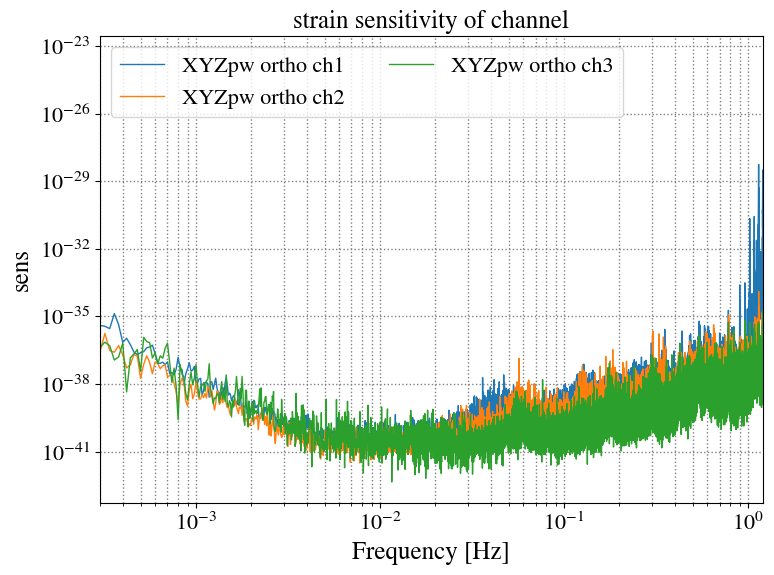

In [18]:
from pcipy import plotting 
plotting.plotconfig(lbsize=18, lgsize=16)
_, axes = plt.subplots(1, 1, figsize=(8, 6))



freqs, n_mat = compute_welch_matrix_td(XYZpw, **welch_kwargs)
_, s, vh = np.linalg.svd(n_mat)
n_mat_ortho = multiple_dot(vh, multiple_dot(n_mat, np.swapaxes(vh, 1, 2).conj()))
freqs, gw_mat = compute_welch_matrix_td(XYZpwGW, **welch_kwargs)
gw_mat_ortho = multiple_dot(vh, multiple_dot(gw_mat, np.swapaxes(vh, 1, 2).conj()))

for ichan in range(3):
    cmpt = 'ch'+'123'[ichan]
    if have_raw:
        axes.loglog(p_tdi2_freqs, 1/tdi2_sh[ichan],
                linewidth=1, label=r'TDI file ortho '+cmpt)
    sens = 1/np.abs(gw_mat_ortho[:,ichan,ichan]/n_mat_ortho[:,ichan,ichan])
    #sens = 1/np.abs(gw_mat_ortho[:,ichan,ichan]/s[:,ichan])
    axes.loglog(freqs, sens,
                linewidth=1, label=r'XYZpw ortho '+cmpt)

axes.legend(loc='upper left', ncol=2)
axes.set_xlabel("Frequency [Hz]")
axes.set_ylabel(r"sens")
axes.set_xlim([3e-4, 1.2])
#axes.set_ylim([3e-19, 1e-13])
axes.grid(linewidth=1, which='both', color='gray', linestyle='dotted')
axes.set_title("strain sensitivity of channel")
plt.show()

/var/folders/1w/n0238s6j1jg6wk95mcbt0s5c0000gp/T/ipykernel_19899/2999998489.py:42: RuntimeWarning: invalid value encountered in divide
  sens = 1/np.abs(gw_mat_ortho[:,iplot,jplot]/n_mat_ortho[:,iplot,jplot])


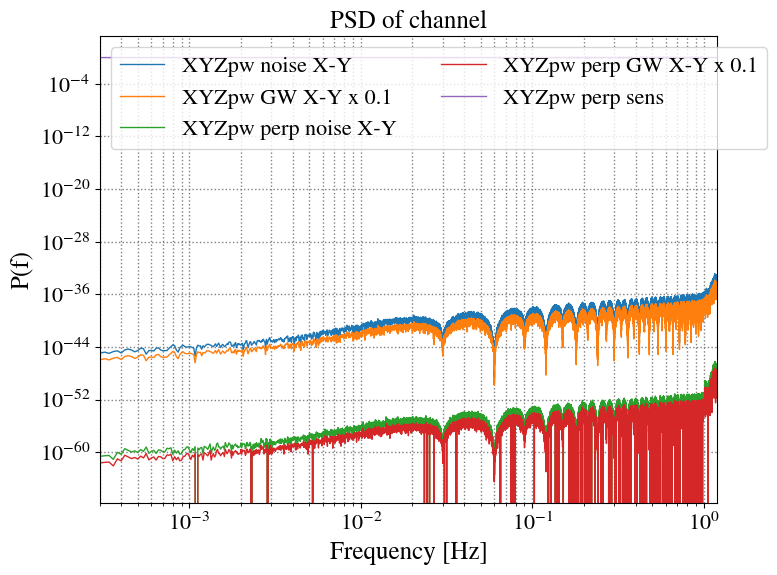

In [19]:
from pcipy import plotting 
plotting.plotconfig(lbsize=18, lgsize=16)
_, axes = plt.subplots(1, 1, figsize=(8, 6))
iplot=0
jplot=1

fac=1e-1

cmpt = 'XYZ'[iplot]+'-'+'XYZ'[jplot]
cmptG = 'XYZ'[iplot]+'-'+'XYZ'[jplot]+' x '+str(fac)
if have_raw:
    axes.loglog(p_tdi2_freqs, np.abs(p_tdi2_n_mat[:,iplot,jplot]),
                linewidth=1, label=r'TDI noise '+cmpt)
    axes.loglog(p_tdi2_freqs, np.abs(p_tdi2_gw_mat[:,iplot,jplot])*fac,
                linewidth=1, label=r'TDI GW '+cmptG)
if 0:
    x=[np.linalg.det(m) for m in p_tdi2_n_mat]
    axes.loglog(freqs, x,
            linewidth=1, label=r'TDI det')

if 1:
    freqs, n_mat = compute_welch_matrix_td(XYZpw, **welch_kwargs)
    axes.loglog(freqs, np.abs(n_mat[:,iplot,jplot]),
                linewidth=1, label=r'XYZpw noise '+cmpt)
    freqs, gw_mat = compute_welch_matrix_td(XYZpw, **welch_kwargs)
    axes.loglog(freqs, np.abs(gw_mat[:,iplot,jplot])*fac,
                linewidth=1, label=r'XYZpw GW '+cmptG)
    if 0:
        x=[np.linalg.det(m) for m in n_mat]
        axes.loglog(freqs, x,
            linewidth=1, label=r'TDI det')
    
    if 1:
        _, s, vh = np.linalg.svd(n_mat)
        n_mat_ortho = multiple_dot(vh, multiple_dot(n_mat, np.swapaxes(vh, 1, 2).conj()))
        axes.loglog(freqs, np.abs(n_mat_ortho[:,iplot,jplot]),
                    linewidth=1, label=r'XYZpw perp noise '+cmpt)
        gw_mat_ortho = multiple_dot(vh, multiple_dot(gw_mat, np.swapaxes(vh, 1, 2).conj()))
        axes.loglog(freqs, np.abs(gw_mat_ortho[:,iplot,jplot])*fac,
                    linewidth=1, label=r'XYZpw perp GW '+cmptG)
        if 1:
            sens = 1/np.abs(gw_mat_ortho[:,iplot,jplot]/n_mat_ortho[:,iplot,jplot])
            axes.loglog(freqs, sens,
                    linewidth=1, label=r'XYZpw perp sens ')
        if 0:
            x=[np.linalg.det(m) for m in n_mat_ortho]
            axes.loglog(freqs, x,
                linewidth=1, label=r'TDI det')

axes.legend(loc='upper left', ncol=2)
axes.set_xlabel("Frequency [Hz]")
axes.set_ylabel(r"P(f)")
axes.set_xlim([3e-4, 1.2])
#axes.set_ylim([3e-19, 1e-13])
axes.grid(linewidth=1, which='both', color='gray', linestyle='dotted')
axes.set_title("PSD of channel")
plt.show()

In [20]:
sens_list = []
sens_list += [["TDIfile", estimate_sensitivity(None,XYZ_file_noise, XYZ_file_gw, joint=True)]]
sens_list += [["pw", estimate_sensitivity(None,XYZpw,XYZpwGW,joint=True)] ]




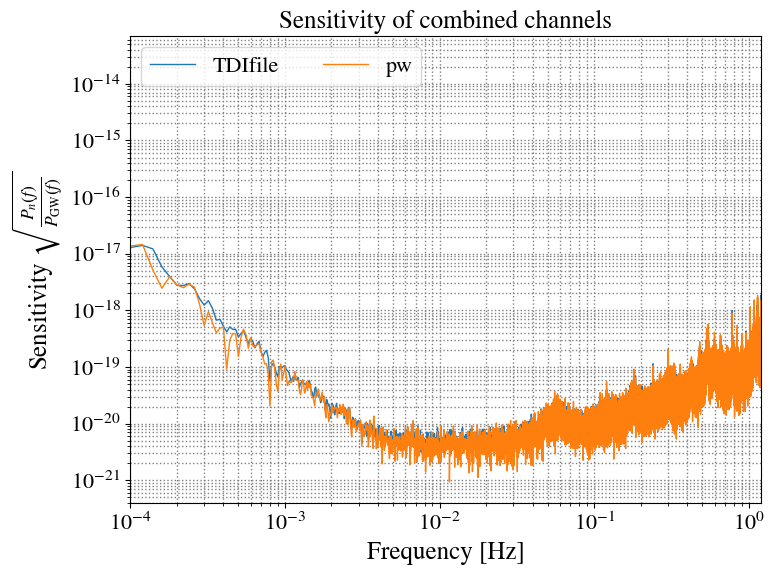

In [21]:
from pcipy import plotting 
plotting.plotconfig(lbsize=18, lgsize=16)
_, axes = plt.subplots(1, 1, figsize=(8, 6))
if have_raw:
    axes.loglog(mean_tdi2_sens[0], np.sqrt(mean_tdi2_sens[1]), 
                linewidth=1, label=r'TDI (raw)',
                color='black')
for j in range(len(sens_list)):
    #print(j)
    axes.loglog(sens_list[j][1][0], np.sqrt(sens_list[j][1][1]), 
                linewidth=1, label=sens_list[j][0], rasterized=True)
axes.legend(loc='upper left', ncol=2)
axes.set_xlabel("Frequency [Hz]")
axes.set_ylabel(r"Sensitivity $\sqrt{\frac{P_{n}(f)}{P_{\mathrm{GW}}(f)}}$")
axes.set_xlim([1e-4, 1.2])
#axes.set_ylim([3e-19, 1e-13])
axes.grid(linewidth=1, which='both', color='gray', linestyle='dotted')
axes.set_title("Sensitivity of combined channels")
plt.show()

In [22]:
sens_list = []
if have_raw and 0:
    sens_list += [["TDIfile'", estimate_sensitivity(None,tdi2_td, tdi2_gw, joint=False)]]
    ytestn=tdi2_td.get_range(skip-125,skip+125+ns)
    ytestgw=tdi2_gw.get_range(skip-125,skip+125+ns)
    sens_list += [["TDIfile[ns]", estimate_sensitivity(None,ytestn,ytestgw,joint=False)]]
#ytestn=get_range(y_td,skip-125,skip+125+ns)
#ytestgw=get_range(y_gw,skip-125,skip+125+ns)
sens_list += [["TDIfile", estimate_sensitivity(None,XYZ_file_noise, XYZ_file_gw, joint=False)]]
ytestn=XYZ_file_noise.get_range(SKIP-125,SKIP+125+ns)
ytestgw=XYZ_file_gw.get_range(SKIP-125,SKIP+125+ns)
sens_list += [["TDIfile[ns]", estimate_sensitivity(None,XYZ_file_noise, XYZ_file_gw, joint=False)]]
sens_list += [["pw", estimate_sensitivity(pwTDIfilter,ytest_n,ytest_gw,joint=False)]]
print(sens_list)

[['TDIfile', (array([0.00000e+00, 2.00000e-05, 4.00000e-05, ..., 1.99996e+00,
       1.99998e+00, 2.00000e+00], shape=(100001,)), array([[4.69340397e-31, 8.02797179e-32, 1.64360001e-34],
       [2.27481937e-31, 1.13055190e-31, 1.59166729e-34],
       [9.37301854e-32, 2.59774475e-32, 1.92578224e-34],
       ...,
       [1.03573406e-24, 2.16385090e-26, 5.75521564e-33],
       [9.90383012e-25, 1.54143433e-26, 7.07026805e-33],
       [9.09571340e-25, 6.81687471e-27, 1.54606596e-32]],
      shape=(100001, 3)))], ['TDIfile[ns]', (array([0.00000e+00, 2.00000e-05, 4.00000e-05, ..., 1.99996e+00,
       1.99998e+00, 2.00000e+00], shape=(100001,)), array([[4.69340397e-31, 8.02797179e-32, 1.64360001e-34],
       [2.27481937e-31, 1.13055190e-31, 1.59166729e-34],
       [9.37301854e-32, 2.59774475e-32, 1.92578224e-34],
       ...,
       [1.03573406e-24, 2.16385090e-26, 5.75521564e-33],
       [9.90383012e-25, 1.54143433e-26, 7.07026805e-33],
       [9.09571340e-25, 6.81687471e-27, 1.54606596e-32]],

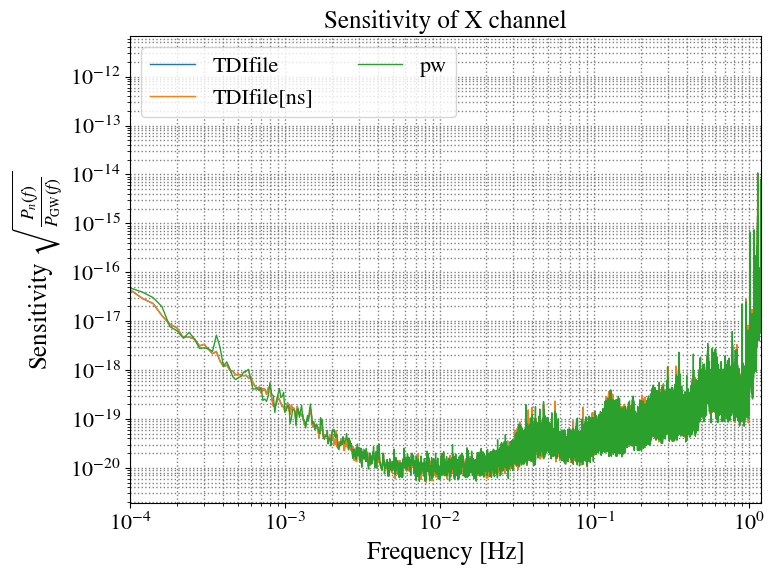

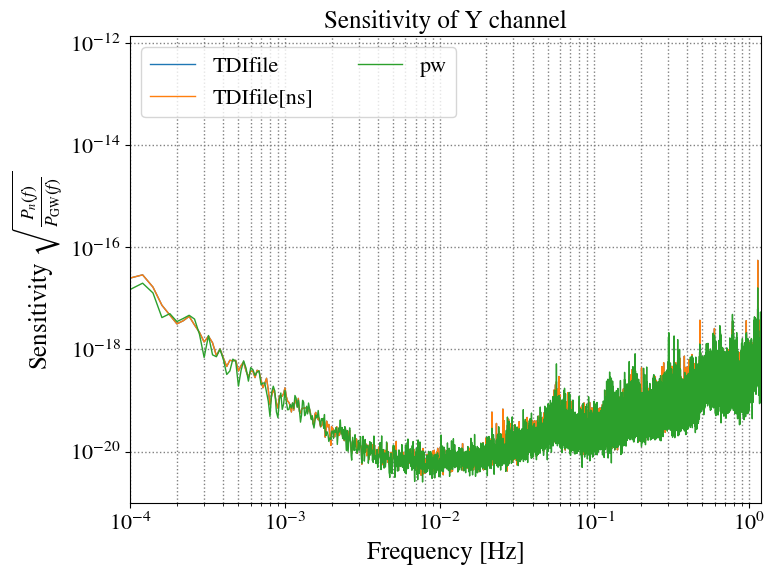

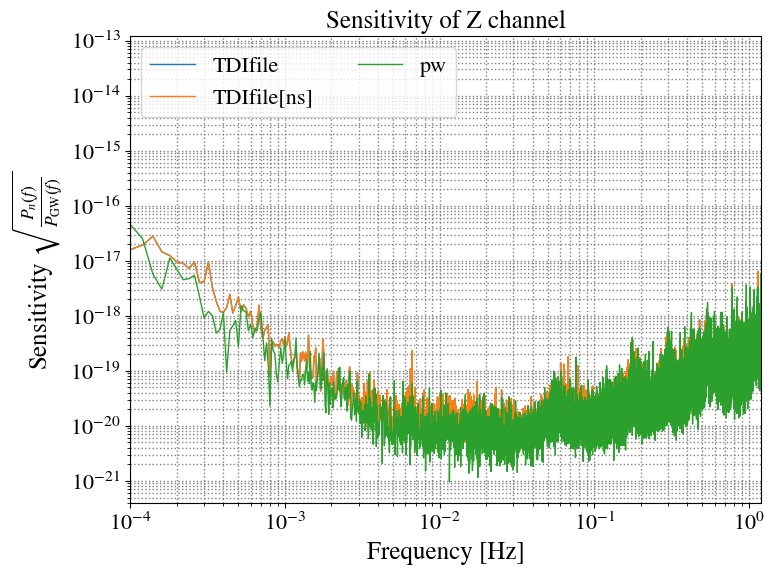

In [23]:
from pcipy import plotting 
for ix in range(3):
    plotting.plotconfig(lbsize=18, lgsize=16)
    _, axes = plt.subplots(1, 1, figsize=(8, 6))

    if have_raw: 
        axes.loglog(mean_tdi2_sens[0], np.sqrt(1/tdi2_sh[ix]), 
                    linewidth=1, label=r'TDI (raw)',
                    color='black')
    for j in range(len(sens_list)):
        #print(j)
        axes.loglog(sens_list[j][1][0], np.sqrt(sens_list[j][1][1][:,ix])*1**j, 
                    linewidth=1, label=sens_list[j][0], rasterized=True)
    axes.legend(loc='upper left', ncol=2)
    axes.set_xlabel("Frequency [Hz]")
    axes.set_ylabel(r"Sensitivity $\sqrt{\frac{P_{n}(f)}{P_{\mathrm{GW}}(f)}}$")
    axes.set_xlim([1e-4, 1.2])
    #axes.set_ylim([3e-19, 1e-13])
    axes.grid(linewidth=1, which='both', color='gray', linestyle='dotted')
    axes.set_title("Sensitivity of "+'XYZ'[ix]+" channel")
    plt.show()

### Now check what is developed above with what we have in the repo now


In [24]:
#HACK:  I have set the "strainPSD" to 2 here in order to get results which look consistent 
#       with the analytic response based sensitivity and other sensitivity plots from EC's work. 
#       I remember that this kind of factor was something that EC struggled with and ultimately
#       resolved. We need to return to this to verify.

sens_list = []
sens_list += [["TDIfile", estimate_sensitivity(None,XYZ_file_noise, XYZ_file_gw, joint=True)]]
sens_list += [["pw", estimate_sensitivity(pwTDIfilter,ytest_n,ytest_gw,joint=True)]]
sens_list += [["TDIfile(repo)", sensitivity.estimate_sensitivity_empirically(None,XYZ_file_noise, XYZ_file_gw, strainPSD=2,gw_input_names=y_namesGW, joint=True,welch_kwargs=welch_kwargs)]]
sens_list += [["pw(repo)", sensitivity.estimate_sensitivity_empirically(pwTDIfilter,ytest_n,ytest_gw, strainPSD=2, gw_input_names=y_namesGW, joint=True,welch_kwargs=welch_kwargs)]]
#sens_list += [["pw(noGWsim)", sensitivity.estimate_sensitivity(pwTDIfilter,ytest_n,orbits=orbits,joint=True,welch_kwargs=welch_kwargs)]]




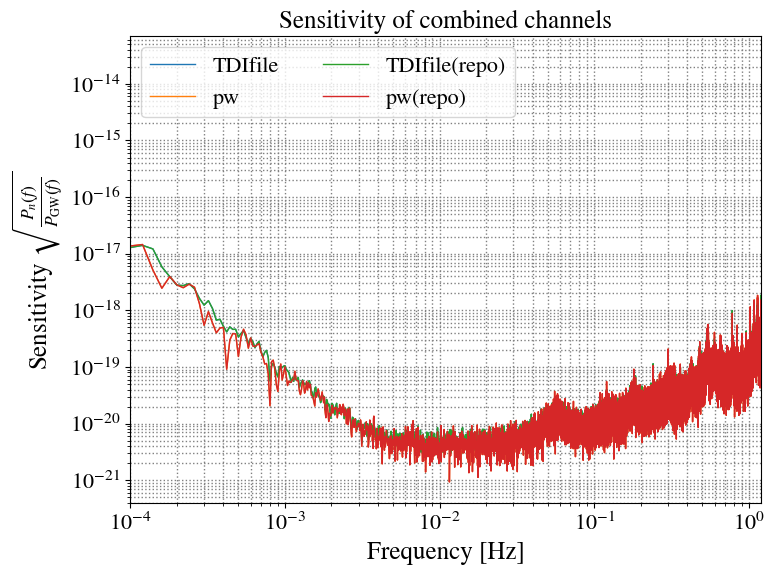

In [25]:
from pcipy import plotting 
plotting.plotconfig(lbsize=18, lgsize=16)
_, axes = plt.subplots(1, 1, figsize=(8, 6))
if have_raw:
    axes.loglog(mean_tdi2_sens[0], np.sqrt(mean_tdi2_sens[1]), 
                linewidth=1, label=r'TDI (raw)',
                color='black')
for j in range(len(sens_list)):
    #print(j)
    axes.loglog(sens_list[j][1][0], np.sqrt(sens_list[j][1][1]), 
                linewidth=1, label=sens_list[j][0], rasterized=True)
axes.legend(loc='upper left', ncol=2)
axes.set_xlabel("Frequency [Hz]")
axes.set_ylabel(r"Sensitivity $\sqrt{\frac{P_{n}(f)}{P_{\mathrm{GW}}(f)}}$")
axes.set_xlim([1e-4, 1.2])
#axes.set_ylim([3e-19, 1e-13])
axes.grid(linewidth=1, which='both', color='gray', linestyle='dotted')
axes.set_title("Sensitivity of combined channels")
plt.show()

### Now try with the backgrounds-based GW response, rather than simulated GWs

In [26]:
coarse_welch_kwargs = {"fs": fs,
          "window": 'blackman',
          "nperseg": nperseg*100,
          "detrend": 'constant',
          "return_onesided": True,
          "scaling": 'density'}
coarse_welch_kwargs['detrend']=None

nside=4 #low for speed in testing. 12 is the default
joint=True
sens_list = []
sens_list += [["TDIfile", estimate_sensitivity(None,XYZ_file_noise, XYZ_file_gw, joint=joint)]]
#sens_list += [["pw", estimate_sensitivity(pwTDIfilter,ytest_n,ytest_gw,joint=True)]]
#sens_list += [["TDIfile(repo)", sensitivity.estimate_sensitivity_empirically(None,XYZ_file_noise, XYZ_file_gw, strainPSD=2, gw_input_names=y_namesGW, joint=True,welch_kwargs=welch_kwargs)]]
sens_list += [["pw(repo)", sensitivity.estimate_sensitivity_empirically(pwTDIfilter,ytest_n,ytest_gw, strainPSD=2, gw_input_names=y_namesGW, joint=joint,welch_kwargs=welch_kwargs)]]
sens_list += [["pw(noGWsim)", sensitivity.estimate_sensitivity(pwTDIfilter,ytest_n,orbits=orbits,joint=joint,welch_kwargs=welch_kwargs,use_TDI_design_matrix=True,nsideGWB=nside)]]
sens_list += [["pw(analytic)", sensitivity.estimate_sensitivity(pwTDIfilter,ytest_n,orbits=orbits,joint=joint,welch_kwargs=welch_kwargs,use_TDI_design_matrix=True,analytic=True,nsideGWB=nside)]]




/Users/jbaker/miniforge3/envs/pcienv/lib/python3.14/site-packages/matplotlib/cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Users/jbaker/miniforge3/envs/pcienv/lib/python3.14/site-packages/matplotlib/cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


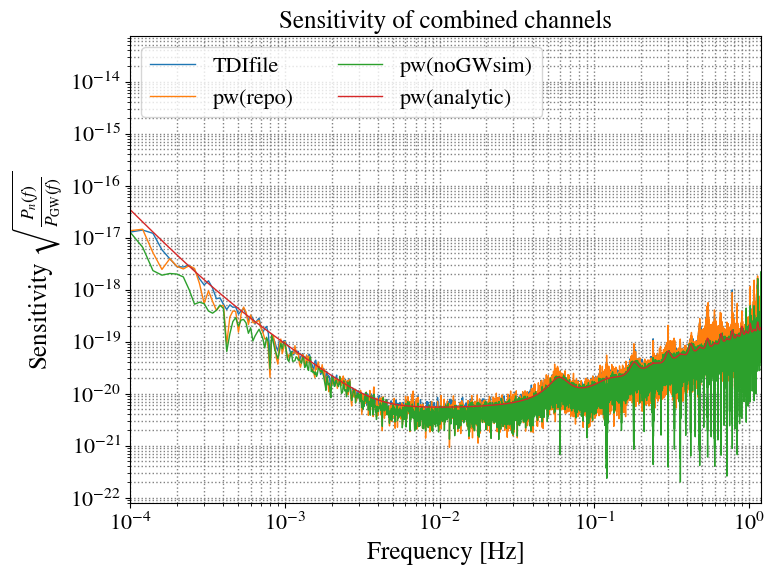

In [27]:
from pcipy import plotting 
plotting.plotconfig(lbsize=18, lgsize=16)
_, axes = plt.subplots(1, 1, figsize=(8, 6))
if have_raw:
    axes.loglog(mean_tdi2_sens[0], np.sqrt(mean_tdi2_sens[1]), 
                linewidth=1, label=r'TDI (raw)',
                color='black')
for j in range(len(sens_list)):
    #print(j)
    axes.loglog(sens_list[j][1][0], np.sqrt(sens_list[j][1][1]), 
                linewidth=1, label=sens_list[j][0], rasterized=True)
axes.legend(loc='upper left', ncol=2)
axes.set_xlabel("Frequency [Hz]")
axes.set_ylabel(r"Sensitivity $\sqrt{\frac{P_{n}(f)}{P_{\mathrm{GW}}(f)}}$")
axes.set_xlim([1e-4, 1.2])
#axes.set_ylim([3e-19, 1e-13])
axes.grid(linewidth=1, which='both', color='gray', linestyle='dotted')
axes.set_title("Sensitivity of combined channels")
plt.show()

## Here we work on development of the sensitivity calculation with analytic GW response calculation. 

At the time of development the repo code, the existing analytic treatment is analyticially computed based on the TDI design matrix. The first step is to express the transfer function for an arbitrary filter. 

For simplicity, to illustrate the transfer function calculation, for a filter specified kernel, we consider a single-channel filter 
    
$ x^i = \sum_{j=0}^{m-1} K_j y^{i+j} $

Then, neglecting the normalizations, the DFT is

$ X^k = \sum_i Z^{ki} x^i $

where $Z=exp(i 2 \pi / N )$.

We want to know the covariance of the result:

$ C_{kk'}= E\left[{X^k}^*X^{k'}\right] = \sum_{ii'}\sum_{jj'}Z^{-ki}Z^{k'i'}K_jK_{j'} E\left[y^{i+j}y^{i'+j'}\right] $

The expecation value on the right is now just a autocorrelation of the input series. For stuationary colored noise,
this autocorrelation depends only on the lag thus, we can write this as

$ R_{|i+j-i'-j'|} = E\left[y^{i+j}y^{i'+j'}\right] $

which is related to the power spectral density by

$ S_k = \sum_i Z^{ki} R_i $

Then, we have

$ C_{kk'} = \sum_{ii'}\sum_{jj'}Z^{-ki}Z{k'i'}K_jK_{j'} Z^{k(i+j-i'-j')} \left(Z^{-k(i+j-i'-j')}R_{|i+j-i'-j'|}\right) $

$ \qquad        = \sum_{i'}\sum_{jj'}Z^{(-k+k')i'}K_jK_{j'} Z^{k(+j-j')}\left(\sum_{i} Z^{k'(i+j-i'-j')}R_{|i+j-i'-j'|} \right)$

A change of variables identifies the part in parenthesis as $S_k$. Then then we can integrate over $i'$ to get a delta function.

$ C_{kk'} = \sum_{jj'}\delta{kk'}K_jK_{j'} Z^{k(+j-j')}S_{k'} $
$         = T_k S_k \delta_{k'k} $

We see the independence of different frequency component expected for stationary noise. In the second line we define the power transfer
function, which we can read off as

$ T_k = \left|W_k\right|^2$

where the channel transfer function is

$ W_k = \sum_j K_j Z^{jk} $

The generalization of this for multi-channel filtering is:

$ x_\alpha^i = \sum_{j=0}^{m-1} K^{\alpha\beta}_j y_\beta^{i+j} $

$ T^{\alpha\alpha'\beta\beta'}_k = {W^{\alpha\beta}_k}^*{W^{\alpha'\beta'}_k}$

$ W^{\alpha\beta}_k = \sum_j K^{\alpha\beta}_j Z^{jk} $



In [28]:
## Developing a new version of the repo code which doesn't rely on the TDI design matrix for the GW response computation
import healpy as hp
from backgrounds import StochasticBackgroundResponse
from backgrounds.tdi import convert
from backgrounds import utils, noise
from lisaconstants.indexing import LINKS

print(LINKS)


def compute_filter_transfer_func(kernel,fdt):
    '''
    Compute the transfer function for a filter specified kernel.
    
    For simplicity, consider a 1_D filter 
    
    $ x^i = \sum_{j=0}^{m-1} K_j y^{i+j} $

    Then, neglecting the normalizations, the DFT is

    $ X^k = \sum_i Z^{ki} x^i $

    where $Z=exp(i 2 \pi / N )$.

    We want to know the covariance of the result:

    $ C_{kk'}= E\left[{X^k}^*X^{k'}\right] = \sum_{ii'}\sum_{jj'}Z^{-ki}Z^{k'i'}K_jK_{j'} E\left[y^{i+j}y^{i'+j'}\right] $

    The expecation value on the right is now just a autocorrelation of the input series. For stuationary colored noise,
    this autocorrelation depends only on the lag thus, we can write this as

    $ R_{|i+j-i'-j'|} = E\left[y^{i+j}y^{i'+j'}\right] $

    which is related to the power spectral density by

    $ S_k = \sum_i Z^{ki} R_i $

    Then, we have

    $ C_{kk'} = \sum_{ii'}\sum_{jj'}Z^{-ki}Z{k'i'}K_jK_{j'} Z^{k(i+j-i'-j')} \left(Z^{-k(i+j-i'-j')}R_{|i+j-i'-j'|}\right) $

    $ \qquad        = \sum_{i'}\sum_{jj'}Z^{(-k+k')i'}K_jK_{j'} Z^{k(+j-j')}\left(\sum_{i} Z^{k'(i+j-i'-j')}R_{|i+j-i'-j'|} \right)$

    A change of variables identifies the part in parenthesis as $S_k$. Then then we can integrate over $i'$ to get a delta function.

    $ C_{kk'} = \sum_{jj'}\delta{kk'}K_jK_{j'} Z^{k(+j-j')}S_{k'} $
    $         = T_k S_k \delta_{k'k} $

    We see the independence of different frequency component expected for stationary noise. In the second line we define the power transfer
    function, which we can read off as

    $ T_k = \left|W_k\right|^2$

    where the channel transfer function is

    $ W_k = \sum_j K_j Z^{jk} $

    The generalization of this for multi-channel filtering is:

    $ x_\alpha^i = \sum_{j=0}^{m-1} K^{\alpha\beta}_j y_\beta^{i+j} $

    $ T^{\alpha\alpha'\beta\beta'}_k = {W^{\alpha\beta}_k}^*{W^{\alpha'\beta'}_k}$

    $ W^{\alpha\beta}_k = \sum_j K^{\alpha\beta}_j Z^{jk} $

    
    Note that we expect the kernel to have shape (Nout,Ndel,Nin), where Nout is the number of output streams from the filter,
    Nin is the number of input streams, and Ndel is the number of delays.
    
    '''
    
    Nout,Ndel,Nin=kernel.shape
    
    Zk=np.exp(-2j*np.pi*fdt)
    
    Wk=np.multiply.outer(np.ones_like(fdt,dtype=complex),np.zeros((Nout,Nin)))
    Zkj=np.ones_like(fdt,dtype=complex)
    for j in range(Ndel):
        #Zkj=np.exp(-2j*fdt*j) ##hack
        Wk+=np.multiply.outer(Zkj,kernel[:,j,:])
        Zkj*=Zk
    
    return Wk
        

def estimate_sensitivity_dev(filt, data_n, orbits, e_gw_mat = None, joint=True, welch_kwargs=None, strainPSD=1.0, analytic = False, nsideGWB=12):
    """
    Estimate the sensitivity of a given dataset against the response to an isotropic SGWB.

    Sensitivity is estimated by explicit computation of the inverse trace of the ratio of the channel simulated GW signal and the channel noise. To scale the sensitivity, we need to know the incident strain PSD value (assumed constant here).

    Parameters
    ----------
    filt : Filter Class.
        If None, data are treated unfilteree.
    data_n : TimeData Class.
        Instrument noise data.
    orbits : str
        Path to orbit file.
    e_gw_mat : GW covariance, optional
        Precalculated GW response from a StochasticBackgroundResponse object from backgrounds. If None, the GW response is evaluated within the class, slowing down calculation time. The default is None.
    joint : bool, optional
        Calculate the joint sensitivity of all channels in the TimeData class. The default is True.
    welch_kwargs : dict, optional
        Dictionary of Welch kwargs for the evaluation of the noise CSD matrix. The default is None.
    strainPSD : float, optional
        Incident strain PSD value (assumed constant here). The default is 1.
    analytic : bool, optional
        Choose between analytic noise covariance matrix, w.r.t. numeric. The default is True.

    Returns
    -------
    freqs : ndarray
        Array of frequencies.
    sens : ndarray
        Array of sensitivity values. If joint == False, it's an array with as many columns as channels.

    """
    if filt is not None:
        e_n = filt.apply_filter(data_n,method='convolve')
    else:
        e_n = data_n

    if welch_kwargs is None:
        nperseg = e_n.n_samples()
        fs = 1/e_n.dt
        welch_kwargs = {"fs": fs,
                  "window": 'blackman',
                  "nperseg": nperseg,
                  "detrend": 'constant',
                  "return_onesided": True,
                  "scaling": 'density'}

    n_channels=e_n.n_channels()
    #print(n_channels,'channels')

    # Welch spectrum matrix from noise data
    freqs, e_n_mat = compute_welch_matrix_td(e_n, **welch_kwargs)

    # GW response to a SGWB background
    if e_gw_mat is None:
        nside = nsideGWB
        npix = hp.nside2npix(nside)
        # skymap = np.ones(npix) * np.sqrt(4 * np.pi / (2*npix))
        # skymap = np.ones(npix) / np.sqrt(4 * np.pi * npix)
        skymap = np.ones(npix) / np.sqrt(2 * npix)

        #  Instantiate SGWB class
        sgwbcls = StochasticBackgroundResponse(skymap=skymap, orbits=orbits, orbit_interp_order=1)
        sgwbcls_t0 = sgwbcls.orbits.t_interp[0]
        t0 = np.ones(1) * (sgwbcls_t0 + 10)  # need an object with a specific length
        # Now let's do it for all links
        gplus, gcross = sgwbcls.compute_correlations(LINKS, freqs, t0)
        bgresponse = gplus + gcross
        # compute TDI response matrix
        # Time delay interferometry performs a linear combination of delayed single-link measurements to cancel laser frequency noise. It outputs three channels that contain all the GW information.

        # Algebraically, this transformation can be written in the (time-)frequency domain using a matrix operation:
        # If you have already computed the single-link responses like above, you can simply compute the TDI transfer function (for X, Y, Z) and then apply it through the equation above:

        bgresponse_ordered = bgresponse[..., convert, :]
        bgresponse_ordered = bgresponse_ordered[..., convert]

        # tdi transfer function at frequencies freqs and time t0
        # this is an array of 3 x 6 matrices (ncombs x nlinks)
        tdimat = sgwbcls.compute_tdi_design_matrix(freqs, t0, gen = '2.0')
        # compute the tdi response in the frequency domain
        # this is an array of 3 x 3 matrices
        #  Rtdi = Mtdi * Rlinks * Mtdi'
        # (ncombs x ncombs) = (ncombs x nlinks) * (nlinks x nlinks) * (nlinks x ncombs)
        # tdiresponse
        e_gw_mat = utils.transform_covariance(tdimat, bgresponse_ordered)
        
        if 1:
            filtGW=filt.restrict(input_names=y_namesGW)
            #print('restricted kernel shape:',filtGW.kernel_compts.shape)
            #print('restricted subfilter kernel shapes:',[subfilt.kernel_compts.shape for subfilt in filtGW.subfilters])
            #print(y_namesGW)
            #print('tdimat shape:',tdimat.shape)
            #Note that we have not addressed the question that the design matrix evolves with time
            #The "tdi_design_matrix" approach uses just a point slightly after t0 as the reference time
            #The piecewise filter approach so far uses the central version of the filter.
            filtermat = compute_filter_transfer_func(filtGW.kernel_compts,freqs*filt.dt)
            #print('filtermat shape:',filtermat.shape)
            #print('tdimat\n',tdimat)
            #print('filternmat\n,',filtermat)
            ##normval=sum(filtermat**2)/filtermat.shape[0]
            e_gw_mat = utils.transform_covariance(filtermat, bgresponse_ordered)
            #e_gw_mat = utils.transform_covariance(filtermat, bgresponse)
            

    else:
        nside = nsideGWB
        npix = hp.nside2npix(nside)
        # skymap = np.ones(npix) * np.sqrt(4 * np.pi / (2*npix))
        # skymap = np.ones(npix) / np.sqrt(4 * np.pi * npix)
        skymap = np.ones(npix) / np.sqrt(2 * npix)

        #  Instantiate SGWB class
        sgwbcls = StochasticBackgroundResponse(skymap=skymap, orbits=orbits, orbit_interp_order=1)
        t0 = np.ones(1) * (sgwbcls.t0 + 10)  # need an object with a specific length

    if analytic==True:
        # OMS amplitudes from LISA Instrument paper
        oms_asds=(6.35e-12, 1.25e-11, 1.42e-12, 3.38e-12, 3.32e-12, 7.90e-12)
        # root sum square of the carrier amplitudes
        Aoms= np.sqrt(oms_asds[0]**2+oms_asds[2]**2+oms_asds[4]**2)
        Atm = 2.24e-15
        noise_classes_analytic = []
        noise_classes_analytic.append(noise.AnalyticOMSNoiseModel(
            freqs, t0, orbits, orbit_interp_order=1, gen="2.0", fs=None, duration=None, oms_isi_carrier_asds=Aoms))
        noise_classes_analytic.append(noise.AnalyticTMNoiseModel(
            freqs, t0, orbits, orbit_interp_order=1, gen="2.0", fs=None, duration=None, tm_isi_carrier_asds=Atm))

        # Compute the TDI spectrum from OMS and TM noise
        cov_tdi_n_comps = [nc.compute_covariances(0.0) for nc in noise_classes_analytic]
        # Compute the full TDI noise spectrum
        e_n_mat = sum(cov_tdi_n_comps)

    # Output sensitivity for each variable, size nfreqs x n_channels
    sens = np.array([np.abs(e_n_mat[:, j, j] / e_gw_mat[:, j, j] * strainPSD) for j in range(n_channels)]).T

    if joint:
        e_n_mat_inv = np.linalg.inv(e_n_mat)
        #print('Calculate trace')
        sens = 1/np.trace(np.linalg.matmul(e_gw_mat,e_n_mat_inv), axis1=1, axis2=2)

    return freqs, sens

[12 23 31 13 32 21]


<>:17: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:17: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
/var/folders/1w/n0238s6j1jg6wk95mcbt0s5c0000gp/T/ipykernel_19899/2323485276.py:17: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
  $ x^i = \sum_{j=0}^{m-1} K_j y^{i+j} $


In [45]:
coarse_welch_kwargs = {"fs": fs,
          "window": 'blackman',
          "nperseg": nperseg//50,
          "detrend": 'constant',
          "return_onesided": True,
          "scaling": 'density'}
coarse_welch_kwargs['detrend']=None
joint=True
nside=5
sens_list = []
sens_list += [["pw(noGWsim)", sensitivity.estimate_sensitivity(pwTDIfilter,ytest_n,orbits=orbits,joint=joint,welch_kwargs=coarse_welch_kwargs,nsideGWB=nside,use_TDI_design_matrix=True)]]
sens_list += [["pw(dev)", estimate_sensitivity_dev(pwTDIfilter,ytest_n,orbits=orbits,joint=joint,welch_kwargs=coarse_welch_kwargs,nsideGWB=nside)]]
#sens_list += [["pw(new__inrepo)", sensitivity.estimate_sensitivity(pwTDIfilter,ytest_n,orbits=orbits,joint=joint,welch_kwargs=welch_kwargs,nsideGWB=nside,use_TDI_design_matrix=False)]]
sens_list += [["pw(analytic)", sensitivity.estimate_sensitivity(pwTDIfilter,ytest_n,orbits=orbits,joint=joint,welch_kwargs=coarse_welch_kwargs,analytic=True,use_TDI_design_matrix=True,nsideGWB=nside)]]


/var/folders/1w/n0238s6j1jg6wk95mcbt0s5c0000gp/T/ipykernel_19899/2323485276.py:226: RuntimeWarning: divide by zero encountered in divide
  sens = 1/np.trace(np.linalg.matmul(e_gw_mat,e_n_mat_inv), axis1=1, axis2=2)
/var/folders/1w/n0238s6j1jg6wk95mcbt0s5c0000gp/T/ipykernel_19899/2323485276.py:226: RuntimeWarning: invalid value encountered in divide
  sens = 1/np.trace(np.linalg.matmul(e_gw_mat,e_n_mat_inv), axis1=1, axis2=2)


/Users/jbaker/miniforge3/envs/pcienv/lib/python3.14/site-packages/matplotlib/cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Users/jbaker/miniforge3/envs/pcienv/lib/python3.14/site-packages/matplotlib/cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


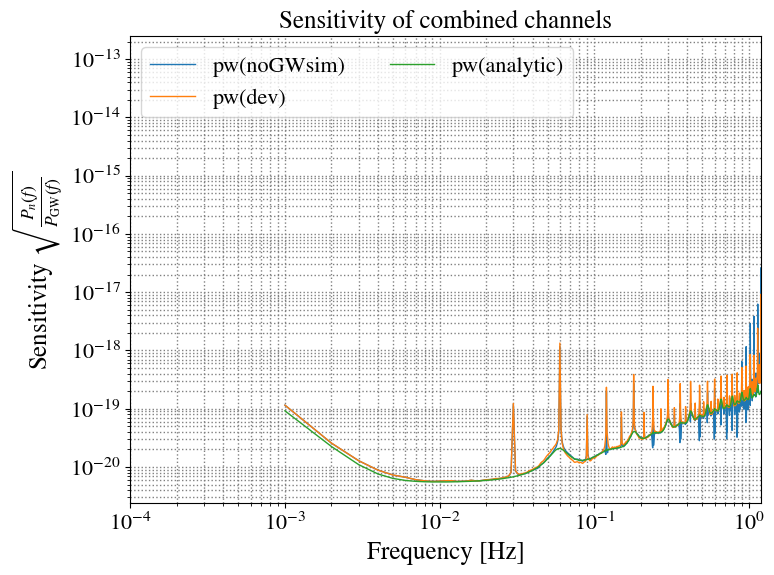

In [46]:
from pcipy import plotting 
plotting.plotconfig(lbsize=18, lgsize=16)
_, axes = plt.subplots(1, 1, figsize=(8, 6))
if have_raw:
    axes.loglog(mean_tdi2_sens[0], np.sqrt(mean_tdi2_sens[1]), 
                linewidth=1, label=r'TDI (raw)',
                color='black')
for j in range(len(sens_list)):
    #print(j)
    axes.loglog(sens_list[j][1][0], np.sqrt(sens_list[j][1][1]), 
                linewidth=1, label=sens_list[j][0], rasterized=True)
axes.legend(loc='upper left', ncol=2)
axes.set_xlabel("Frequency [Hz]")
axes.set_ylabel(r"Sensitivity $\sqrt{\frac{P_{n}(f)}{P_{\mathrm{GW}}(f)}}$")
axes.set_xlim([1e-4, 1.2])
#axes.set_ylim([3e-19, 1e-13])
axes.grid(linewidth=1, which='both', color='gray', linestyle='dotted')
axes.set_title("Sensitivity of combined channels")
plt.show()